# C3 climate risk in euros

Track C, Apetit Climate & Nature Navigator 2026.

This notebook turns the 2041–60 yield projection into money and emissions. When contract farms deliver less than the contracted volume, Apetit buys the gap on the market. That costs a premium over the contract price, and the imported produce brings its own emissions. It is step 9 of the farm climate-risk recipe.

For every simulated season:

- shortfall = contracted volume minus what the 2025 contract parcels produce, if positive;
- extra cost = shortfall times contract price times replacement premium;
- extra emissions = shortfall times the import's emission factor.

Each climate scenario is priced with the economic scenarios the package pairs it with: three NGFS scenarios each for ssp126 and ssp245, and current policies for ssp585. "Today" means the same farms in the 1991–2020 climate, so the difference from today is what climate change adds.

Two things are deliberately left out of the cost. A surplus in a good season isn't credited. Supply from Foodhills in Sweden isn't counted as a replacement, because how much Bjuv could redirect is unknown; section 6 shows its potential as an insight instead.

It needs the outputs of `c2_yield_projection.ipynb`. The code is in `riskprice.py`. All prices are 2025 euros.

## 0. Setup

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import riskprice as rp

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
PKG = Path(os.environ.get("CCN_PKG", "../APETIT_CLIMATE_NATURE_NAVIGATOR_2026")).resolve()
OUT, RESULTS = Path("outputs"), Path("results")
assert (OUT / "yield_projection_draws.parquet").exists(), "run c2_yield_projection.ipynb first"

UNITS = [("FI_SW", "pea"), ("SE_SKANE", "pea"), ("FI_SW", "turnip_rape"),
         ("FI_SW", "potato"), ("FI_SW", "carrot"), ("FI_SW", "spinach")]
LABEL = {("FI_SW", "pea"): "Pea, Finland", ("SE_SKANE", "pea"): "Pea, Sweden", ("FI_SW", "turnip_rape"): "Turnip rape, Finland",
         ("FI_SW", "potato"): "Potato, Finland", ("FI_SW", "carrot"): "Carrot, Finland", ("FI_SW", "spinach"): "Spinach, Finland"}
SSP = ["baseline", "ssp126", "ssp245", "ssp585"]
SSP_NAME = {"baseline": "today", "ssp126": "ssp126", "ssp245": "ssp245", "ssp585": "ssp585"}

## 1. Inputs

### Contracted volume

The 2025 contract area of each crop times the normal yield of today's farms: the yield model run on the 30 seasons of 1991–2020, with today's practice and the trend at 2026.

In [2]:
draws = pd.read_parquet(OUT / "yield_projection_draws.parquet")
contracted = rp.contracted_volume(draws)
show = contracted.copy(); show.index = [LABEL[(r, c)] for r, c in zip(show["region"], show["crop"])]
show[["area_ha", "normal_yield_t_ha", "contracted_t"]].round(2)

,area_ha,normal_yield_t_ha,contracted_t
"Carrot, Finland",226.72,55.61,12607.75
"Pea, Finland",2014.66,3.53,7118.65
"Potato, Finland",328.03,30.62,10043.01
"Spinach, Finland",359.11,22.49,8076.04
"Turnip rape, Finland",5024.65,1.56,7823.17
"Pea, Sweden",4973.10,3.47,17246.24


### Prices and premiums

The 2025 contract price and replacement premium per crop come from `contract_prices_and_replacement_premiums.csv`. For frozen vegetables, the premium rises by the increase in each NGFS scenario's frozen-vegetable import premium between 2025 and 2041–60 (`transition_scenarios.csv`). Turnip rape is an oilseed, so its premium stays as it is. The package marks these scenario paths as illustrative.

In [3]:
prices = pd.read_csv(PKG / "data/05_scenarios/contract_prices_and_replacement_premiums.csv")
transition = pd.read_csv(PKG / "data/05_scenarios/transition_scenarios.csv")
prem = rp.premiums(prices, transition)
p = prem.copy(); p["unit"] = [LABEL[(r, c)] for r, c in zip(p["region"], p["crop"])]
pt = p.pivot_table(index="unit", columns="ngfs", values="premium").mul(100)
pt.insert(0, "contract price (EUR/t)", p.groupby("unit")["contract_price_eur_t"].first())
pt.loc[[LABEL[u] for u in UNITS]].round(1)

ngfs,contract price (EUR/t),below_2c,current_policies,delayed_transition,fragmented_world,low_demand,ndcs,net_zero_2050,today
unit,,,,,,,,,
"Pea, Finland",420.0,57.9,60.2,55.9,59.8,57.1,59.5,55.5,55.0
"Pea, Sweden",410.0,57.9,60.2,55.9,59.8,57.1,59.5,55.5,55.0
"Turnip rape, Finland",470.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
"Potato, Finland",230.0,47.9,50.2,45.9,49.8,47.1,49.5,45.5,45.0
"Carrot, Finland",290.0,42.9,45.2,40.9,44.8,42.1,44.5,40.5,40.0
"Spinach, Finland",380.0,62.9,65.2,60.9,64.8,62.1,64.5,60.5,60.0


In [4]:
transition.drop_duplicates("scenario")[["scenario", "ngfs_category", "physical_pathway_proxy"]].rename(
    columns={"scenario": "NGFS scenario", "ngfs_category": "category", "physical_pathway_proxy": "climate scenario it is paired with"})

,NGFS scenario,category,climate scenario it is paired with
0,net_zero_2050,orderly,ssp126
7,below_2c,orderly,ssp126
14,low_demand,orderly,ssp126
21,delayed_transition,disorderly,ssp245
28,fragmented_world,"too little, too late",ssp245
35,ndcs,hot house,ssp245
42,current_policies,hot house,ssp585


### Import emission factors

There is no factor for imported frozen peas in the package, so each import factor is built from factors it does have:

- Vegetables: the farm-gate footprint of a comparable grower, plus transport on the package's own route for frozen vegetables bought from Belgium (median truck and ferry distances over its shipment records). For peas, the comparable grower is the Swedish pea factor. For potato, carrot and spinach, the Finnish factors stand in for an EU grower.
- Turnip rape: the average farm-gate factor of the Baltic origins Apetit already imports from, plus their median truck and bulk-ship distances.

Freezing is left out on both sides. The supplier's freezing roughly replaces Apetit's own processing, which also doesn't happen for the missing volume.

In [5]:
ef = pd.read_csv(PKG / "data/01_master/emission_factor_library.csv").set_index("ef_id")["kgco2e_per_unit"]
ship = pd.read_csv(PKG / "data/02_raw_feeds/shipments.csv", dtype={"ref_doc": str})
erp = pd.read_csv(PKG / "data/02_raw_feeds/erp_purchase_lines_2021_2025.csv", dtype={"doc_no": str})
mat = pd.read_csv(PKG / "data/01_master/materials.csv")
legs = (ship[ship["direction"].eq("inbound")]
        .merge(erp.drop_duplicates("doc_no")[["doc_no", "material_id", "origin_country"]], left_on="ref_doc", right_on="doc_no")
        .merge(mat[["material_id", "material_group"]], on="material_id"))
km = legs.groupby(["material_group", "origin_country", "ef_id"])["km"].median()

veg_route = km.loc["vegetable_bought", "BE"]                     # truck-reefer and Ro-Pax legs, Belgium
veg_transport = sum(veg_route[e] * ef[e] for e in veg_route.index) / 1000          # kg CO2e per kg
baltic = ["EE", "LV", "LT"]
rape_transport = np.mean([sum(km.loc["oilseed", o][e] * ef[e] for e in km.loc["oilseed", o].index) / 1000 for o in baltic])
rape_farm = np.mean([ef[f"EF-RAP-{o}"] for o in baltic])

IMPORT_EF = {("FI_SW", "pea"): ef["EF-VEG-PEA-SE"] + veg_transport, ("SE_SKANE", "pea"): ef["EF-VEG-PEA-SE"] + veg_transport,
             ("FI_SW", "potato"): ef["EF-VEG-POT-FI"] + veg_transport, ("FI_SW", "carrot"): ef["EF-VEG-CAR-FI"] + veg_transport,
             ("FI_SW", "spinach"): ef["EF-VEG-SPI-FI"] + veg_transport, ("FI_SW", "turnip_rape"): rape_farm + rape_transport}
print("Belgian frozen-vegetable route:", {e: f"{v:.0f} km" for e, v in veg_route.items()}, f"-> {veg_transport:.3f} kg CO2e/kg")
print(f"Baltic oilseed routes: transport {rape_transport:.3f} kg CO2e/kg, farm gate {rape_farm:.3f}")
pd.Series({LABEL[u]: v for u, v in IMPORT_EF.items()}, name="import factor (t CO2e per t)").round(3).to_frame()

Belgian frozen-vegetable route: {'EF-TKM-ROPAX': '1000 km', 'EF-TKM-TRUCK-REEFER': '1342 km'} -> 0.218 kg CO2e/kg
Baltic oilseed routes: transport 0.016 kg CO2e/kg, farm gate 1.337


,import factor (t CO2e per t)
"Pea, Finland",0.488
"Pea, Sweden",0.488
"Potato, Finland",0.328
"Carrot, Finland",0.308
"Spinach, Finland",0.358
"Turnip rape, Finland",1.352


## 2. Price every simulated season

Every season and simulated outcome from the projection gets a shortfall, a cost under each paired NGFS scenario, and import emissions.

In [6]:
priced = rp.price_draws(draws, contracted, prem, IMPORT_EF)
print(len(priced), "priced seasons;", priced.groupby(["scenario", "ngfs"]).size().rename("rows").to_dict())

72000 priced seasons; {('baseline', 'today'): 9000, ('ssp126', 'below_2c'): 9000, ('ssp126', 'low_demand'): 9000, ('ssp126', 'net_zero_2050'): 9000, ('ssp245', 'delayed_transition'): 9000, ('ssp245', 'fragmented_world'): 9000, ('ssp245', 'ndcs'): 9000, ('ssp585', 'current_policies'): 9000}


## 3. Cost per crop

The expected extra cost per year and the cost in a 1-in-10 bad year (the 90th percentile), in thousands of euros. For ssp126 and ssp245 the figure is the average over their three paired NGFS scenarios; the full split is in `results/climate_risk_eur.csv`.

In [7]:
summ = rp.summarise(priced)
ssp_level = summ.groupby(["region", "crop", "scenario"], sort=False).mean(numeric_only=True).reset_index()
ssp_level["unit"] = [LABEL[(r, c)] for r, c in zip(ssp_level["region"], ssp_level["crop"])]
cost = (ssp_level.pivot(index="unit", columns="scenario", values="expected_cost_eur")[SSP] / 1000).add_prefix("expected kEUR/yr ")
tail = (ssp_level.pivot(index="unit", columns="scenario", values="one_in_ten_cost_eur")[SSP] / 1000).add_prefix("1-in-10 kEUR ")
cost.join(tail).loc[[LABEL[u] for u in UNITS]].rename(columns=lambda c: c.replace("baseline", "today")).round(1)

scenario,expected kEUR/yr today,expected kEUR/yr ssp126,expected kEUR/yr ssp245,expected kEUR/yr ssp585,1-in-10 kEUR today,1-in-10 kEUR ssp126,1-in-10 kEUR ssp245,1-in-10 kEUR ssp585
unit,,,,,,,,
"Pea, Finland",98.8,121.8,128.4,141.6,320.9,419.5,468.2,495.5
"Pea, Sweden",151.5,168.6,169.2,164.9,466.6,510.9,515.0,485.8
"Turnip rape, Finland",16.3,18.7,19.3,22.8,50.3,59.4,61.7,64.9
"Potato, Finland",36.9,39.9,43.6,51.9,103.1,115.3,121.5,148.9
"Carrot, Finland",43.4,46.7,49.3,53.1,134.9,138.4,142.8,149.1
"Spinach, Finland",53.4,55.9,45.7,33.8,163.0,160.5,152.0,128.4


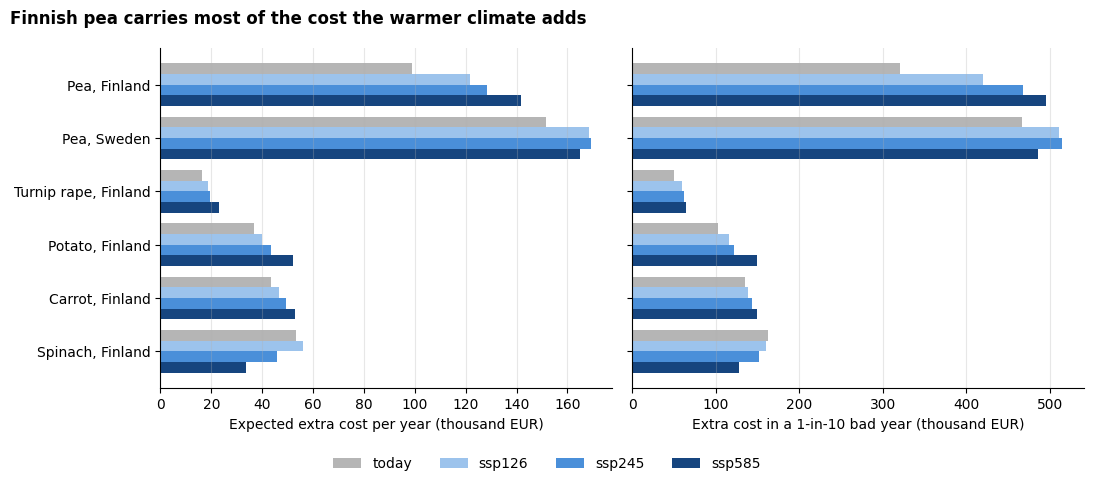

In [8]:
colors = {"baseline": "#b5b5b5", "ssp126": "#9cc3ec", "ssp245": "#4a8fd9", "ssp585": "#16457f"}
units = [LABEL[u] for u in UNITS][::-1]
y = np.arange(len(units)); h = 0.2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for i, s in enumerate(SSP):
    e = ssp_level[ssp_level["scenario"].eq(s)].set_index("unit").loc[units]
    off = (1.5 - i) * h
    ax1.barh(y + off, e["expected_cost_eur"] / 1000, h, color=colors[s], label=SSP_NAME[s])
    ax2.barh(y + off, e["one_in_ten_cost_eur"] / 1000, h, color=colors[s])
ax1.set_yticks(y); ax1.set_yticklabels(units)
ax1.set_xlabel("Expected extra cost per year (thousand EUR)"); ax2.set_xlabel("Extra cost in a 1-in-10 bad year (thousand EUR)")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Finnish pea carries most of the cost the warmer climate adds", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(RESULTS / "climate_risk_eur.png", dpi=150, bbox_inches="tight")
plt.show()

Swedish pea has the largest cost even today, simply because it is the largest volume. What the warmer climate adds falls mostly on Finnish pea, whose expected cost rises by about 25–45% depending on the scenario. Potato and carrot rise a little. Turnip rape's cost stays small because its replacement premium is only 8%. Spinach gets cheaper, because its short early season escapes most of the summer stress.

## 4. Total across crops

All crops together, season by season. Seasons line up across crops because every crop uses the same past seasons, so a season that is bad everywhere is bad in the total too.

In [9]:
tot = (priced.groupby(["scenario", "ngfs", "season", "rep"], sort=False)[["extra_cost_eur", "import_tco2e"]].sum().reset_index())
by_ngfs = tot.groupby(["scenario", "ngfs"], sort=False).agg(
    expected_cost_keur=("extra_cost_eur", lambda s: s.mean() / 1000),
    one_in_ten_cost_keur=("extra_cost_eur", lambda s: s.quantile(0.9) / 1000),
    expected_import_tco2e=("import_tco2e", "mean"),
    one_in_ten_import_tco2e=("import_tco2e", lambda s: s.quantile(0.9))).reset_index()
today = by_ngfs[by_ngfs["scenario"].eq("baseline")].iloc[0]
by_ngfs["climate adds, expected kEUR/yr"] = by_ngfs["expected_cost_keur"] - today["expected_cost_keur"]
by_ngfs.round(1)

,scenario,ngfs,expected_cost_keur,one_in_ten_cost_keur,expected_import_tco2e,one_in_ten_import_tco2e,"climate adds, expected kEUR/yr"
0,baseline,today,400.2,948.2,1439.4,3719.4,0.0
1,ssp126,below_2c,459.8,929.2,1598.7,3900.1,59.6
2,ssp126,low_demand,453.7,916.6,1598.7,3900.1,53.5
3,ssp126,net_zero_2050,441.1,890.0,1598.7,3900.1,40.8
4,ssp245,delayed_transition,435.8,934.0,1611.6,4006.6,35.6
5,ssp245,fragmented_world,466.6,998.9,1611.6,4006.6,66.4
6,ssp245,ndcs,464.0,993.4,1611.6,4006.6,63.8
7,ssp585,current_policies,468.2,1048.2,1742.5,4144.0,68.0


Read the "climate adds" column as the part of the yearly cost that comes from the warmer climate rather than from ordinary bad seasons, which happen today too. Within each climate scenario, the NGFS scenarios differ only through the import premium, yet under ssp245 that moves the climate addition from about €36k to €66k a year. How import prices develop matters about as much as how much the climate warms.

## 5. Emissions from replacement imports

Replacement imports add to Scope 3 category 1 (purchased goods). Expected tonnes of CO2e per year, by crop.

In [10]:
em = (ssp_level.pivot(index="unit", columns="scenario", values="expected_import_tco2e")[SSP]).rename(columns=SSP_NAME)
em.loc[[LABEL[u] for u in UNITS]].round(1)

scenario,today,ssp126,ssp245,ssp585
unit,,,,
"Pea, Finland",209.0,249.1,255.7,273.4
"Pea, Sweden",328.0,353.2,345.1,326.2
"Turnip rape, Finland",586.2,671.1,693.5,821.6
"Potato, Finland",116.9,121.4,128.5,147.7
"Carrot, Finland",115.4,118.5,120.8,124.8
"Spinach, Finland",83.9,85.3,67.9,48.8


Turnip rape dominates here even though its euro cost is small: imported Baltic rapeseed has a footprint of about 1.35 t CO2e per tonne, far above vegetables. These emissions are small next to the farms' own, but they are a climate-driven addition that appears in the inventory without any change in what Apetit does.

## 6. Insight: could Foodhills cover Finnish pea shortfalls?

Not priced. In each simulated season, compare the Finnish pea shortfall with the Swedish pea surplus in the same season (production above Sweden's contracted volume). Because both regions use the same past season, a summer that was bad in both stays bad in both. Seasonal values are averages over the simulated outcomes, so this reflects the weather, not chance farm-level noise.

This is an upper bound. It assumes every tonne of Swedish surplus could be frozen at Bjuv and sent to Finland, which depends on Bjuv's spare capacity in harvest weeks, grower contracts and transport, none of which the package describes.

In [11]:
pea = draws[draws["crop"].eq("pea") & ~draws["scenario"].str.endswith("_run")]
season = pea.groupby(["scenario", "region", "season"])["production_t"].mean().unstack("region")
ct = contracted[contracted["crop"].eq("pea")].set_index("region")["contracted_t"]
fi_short = (ct["FI_SW"] - season["FI_SW"]).clip(lower=0)
se_surplus = (season["SE_SKANE"] - ct["SE_SKANE"]).clip(lower=0)
fi_price = prem[(prem["region"].eq("FI_SW")) & (prem["crop"].eq("pea")) & (prem["ngfs"].eq("today"))]["contract_price_eur_t"].iat[0]
rows = []
for s in SSP:
    fs, ss = fi_short.loc[s], se_surplus.loc[s]
    bad = fs > 0.1 * ct["FI_SW"]
    covered = np.minimum(fs, ss)
    rows.append({"climate": SSP_NAME[s], "seasons": len(fs), "Finnish pea short by >10%": int(bad.sum()),
                 "of which Sweden had a surplus": int((bad & (ss > 0)).sum()),
                 "share of Finnish shortfall Swedish surplus could cover (%)": 100 * covered.sum() / max(fs.sum(), 1e-9),
                 "premium avoided at most (kEUR/yr)": covered.mean() * fi_price * 0.55 / 1000})
insight = pd.DataFrame(rows).set_index("climate")
insight.round(1)

,seasons,Finnish pea short by >10%,of which Sweden had a surplus,share of Finnish shortfall Swedish surplus could cover (%),premium avoided at most (kEUR/yr)
climate,,,,,
today,30,8,5,38.9,37.8
ssp126,30,9,4,39.8,46.2
ssp245,30,8,4,33.9,40.3
ssp585,30,9,3,34.4,43.6


Finnish pea falls more than 10% short in 8–9 of every 30 seasons. Sweden had a surplus in roughly a third to two-thirds of those, and across all seasons its surplus could cover about a third of the Finnish shortfall. That is worth at most about €40–46k a year in avoided premium, against an expected Finnish pea cost of €100–140k. It is a partial hedge, not full cover, and the ceiling is before transport and capacity limits. Because the Swedish crop is barely affected by the warming, a sourcing arrangement between Säkylä and Bjuv is worth investigating with Apetit's sourcing team.

## 7. Assumptions

Every number the pricing rests on, with its source. These are what a reviewer approves or changes; changing one means re-running this notebook.

In [12]:
A = []
for u in UNITS:
    r, c = u; item = rp.PRICE_ITEM[u]
    row = prem[(prem["region"].eq(r)) & (prem["crop"].eq(c)) & (prem["ngfs"].eq("today"))].iloc[0]
    A.append({"assumption": f"contract price, {LABEL[u]}", "value": row["contract_price_eur_t"], "unit": "EUR/t",
              "source": f"contract_prices_and_replacement_premiums.csv, {item}, 2025"})
    A.append({"assumption": f"replacement premium today, {LABEL[u]}", "value": row["premium"], "unit": "fraction of price",
              "source": f"contract_prices_and_replacement_premiums.csv, {item}, 2025"})
    A.append({"assumption": f"import emission factor, {LABEL[u]}", "value": round(IMPORT_EF[u], 4), "unit": "t CO2e per t",
              "source": "emission_factor_library.csv farm-gate factor plus transport on package shipment routes (section 1)"})
    cv = contracted[(contracted["region"].eq(r)) & (contracted["crop"].eq(c))].iloc[0]
    A.append({"assumption": f"contracted volume, {LABEL[u]}", "value": round(cv["contracted_t"], 1), "unit": "t",
              "source": "2025 contract parcels x model yield on 1991-2020 weather (c2_yield_projection)"})
A += [{"assumption": "premium increase by 2041-60 for frozen vegetables", "value": "per NGFS scenario", "unit": "percentage points",
       "source": "transition_scenarios.csv frozen_veg_import_premium_pct, mean of 2045 and 2050 minus 2025 (illustrative values)"},
      {"assumption": "price level", "value": 2025, "unit": "year", "source": "constant 2025 euros"},
      {"assumption": "surplus credited", "value": "no", "unit": "", "source": "design choice"},
      {"assumption": "Foodhills supply as replacement", "value": "not counted", "unit": "", "source": "design choice; see section 6"},
      {"assumption": "domestic farm emissions in a shortfall", "value": "unchanged", "unit": "", "source": "fields are still sown, fertilised and harvested"}]
assumptions = pd.DataFrame(A)
assumptions

,assumption,value,unit,source
0,"contract price, Pea, Finland",420.0,EUR/t,"contract_prices_and_replacement_premiums.csv, ..."
1,"replacement premium today, Pea, Finland",0.55,fraction of price,"contract_prices_and_replacement_premiums.csv, ..."
2,"import emission factor, Pea, Finland",0.4884,t CO2e per t,emission_factor_library.csv farm-gate factor p...
3,"contracted volume, Pea, Finland",7118.6,t,2025 contract parcels x model yield on 1991-20...
4,"contract price, Pea, Sweden",410.0,EUR/t,"contract_prices_and_replacement_premiums.csv, ..."
5,"replacement premium today, Pea, Sweden",0.55,fraction of price,"contract_prices_and_replacement_premiums.csv, ..."
6,"import emission factor, Pea, Sweden",0.4884,t CO2e per t,emission_factor_library.csv farm-gate factor p...
7,"contracted volume, Pea, Sweden",17246.2,t,2025 contract parcels x model yield on 1991-20...
8,"contract price, Turnip rape, Finland",470.0,EUR/t,"contract_prices_and_replacement_premiums.csv, ..."
9,"replacement premium today, Turnip rape, Finland",0.08,fraction of price,"contract_prices_and_replacement_premiums.csv, ..."


## 8. Checks
If any check fails, the notebook stops before writing anything.

In [13]:
checks = {
    "every crop has a contracted volume": len(contracted) == len(UNITS) and (contracted["contracted_t"] > 0).all(),
    "no negative shortfalls, costs or emissions": (priced[["shortfall_t", "extra_cost_eur", "import_tco2e"]] >= 0).all().all(),
    "each climate scenario priced with its paired NGFS scenarios": priced.groupby("scenario")["ngfs"].nunique().to_dict() == {"baseline": 1, "ssp126": 3, "ssp245": 3, "ssp585": 1},
    "today's expected shortfall is small (< 10% of contract)": (summ[summ["scenario"].eq("baseline")]["expected_shortfall_t"] < 0.1 * summ[summ["scenario"].eq("baseline")]["contracted_t"]).all(),
    "every crop and NGFS scenario has 30 seasons x 50 outcomes": (priced.groupby(["region", "crop", "scenario", "ngfs"]).size() == 30 * 50).all(),
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values())

PASS every crop has a contracted volume
PASS no negative shortfalls, costs or emissions
PASS each climate scenario priced with its paired NGFS scenarios
PASS today's expected shortfall is small (< 10% of contract)
PASS every crop and NGFS scenario has 30 seasons x 50 outcomes


## 9. Write the outputs

In [14]:
priced.to_parquet(OUT / "climate_risk_priced.parquet", index=False)        # input to step 10
summ.round(3).to_csv(RESULTS / "climate_risk_eur.csv", index=False)
by_ngfs.round(3).to_csv(RESULTS / "climate_risk_total.csv", index=False)
insight.round(3).to_csv(RESULTS / "foodhills_cover_insight.csv")
assumptions.to_csv(RESULTS / "risk_assumptions.csv", index=False)
import json
_ = (RESULTS / "import_ef.json").write_text(json.dumps({f"{r}/{c}": round(float(v), 6) for (r, c), v in IMPORT_EF.items()}, indent=1))
print(f"outputs/climate_risk_priced.parquet  {(OUT / 'climate_risk_priced.parquet').stat().st_size / 1e6:6.2f} MB")
for f in ["climate_risk_eur.csv", "climate_risk_total.csv", "foodhills_cover_insight.csv", "risk_assumptions.csv", "climate_risk_eur.png"]:
    print(f"results/{f:30s} {(RESULTS / f).stat().st_size / 1e6:6.3f} MB  (versioned)")

outputs/climate_risk_priced.parquet    1.71 MB
results/climate_risk_eur.csv            0.005 MB  (versioned)
results/climate_risk_total.csv          0.001 MB  (versioned)
results/foodhills_cover_insight.csv     0.000 MB  (versioned)
results/risk_assumptions.csv            0.004 MB  (versioned)
results/climate_risk_eur.png            0.063 MB  (versioned)


## Points for the method note

- A shortfall is priced as a market import: the shortfall times the contract price times the replacement premium. Prices and premiums are the package's, in constant 2025 euros. Each climate scenario uses the economic scenarios the package pairs it with.
- The import adds its full emission factor, because the domestic fields are farmed either way. Factors are built from the package's own farm-gate factors and shipment routes.
- "Today" is the same farms in the 1991–2020 climate, so the difference is what the warmer climate adds on top of ordinary bad seasons.
- Surpluses aren't credited, and Foodhills supply isn't counted as a replacement. Its potential is reported as an insight for Apetit to investigate.